# 07. Executive summary

Storyline for management: the business problem, the benchmark, our path, and the answers to the manager's three
questions. Each section gives its message as a title, one plain sentence, one figure, and a folded block of
technical details for questions.

Setup: Cutoff D 12:00, forecast the 24 h of D+1, test 1 Jul 2025 to 30 Jun 2026.

Nothing is fitted here. We read the dataset and the test forecasts saved by 01, 04, 05 and the extension
(run them first). Figures are saved in `reports/figures/`, next to this folder.

## Setup

In [1]:
import sys
sys.path.insert(0, "../../src")

from datetime import date
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Markdown, display
from watt_forecast.data_preprocessing import DAILY_KEYS, HOURLY_KEYS, load_dataset, load_predictions
from watt_forecast.metrics import COLD_DAY_C, PEAK_HOURS, compute_metrics, scorecard, scorecard_daily

In [2]:
# Style shared by every figure: readable on a slide, same colour for a forecast everywhere
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (11, 5), "font.size": 13, "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 12, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.facecolor": "white", "savefig.dpi": 200, "savefig.facecolor": "white", "savefig.bbox": "tight",
})

ACTUAL, RTE_GREY, NO_RTE_GREY = "black", "#7f7f7f", "#c7c7c7"
ACCENT, ACCENT_2 = "#1f6fd1", "#e07b00"  # LightGBM residual, RTE debiased by hour
COLORS = {
    "Lag 7d": NO_RTE_GREY, "LightGBM, no RTE": NO_RTE_GREY, "RTE raw": RTE_GREY,
    "LightGBM residual": ACCENT, "RTE debiased by hour": ACCENT_2,
}


def save(fig, name):
    """Save the figure as reports/figures/<name>.png and show it."""
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()


def say(text):
    display(Markdown(text))


def details(text, source):
    """Folded block for technical questions."""
    say(f"<details><summary>Technical details</summary>\n\n{text}\n\nSource: {source}.\n\n</details>")


def gw(mw, digits=2):
    return f"{mw / 1000:.{digits}f} GW"


def mw(x):
    return f"{x:,.0f} MW"


def md_table(table):
    """Markdown table of a polars DataFrame (values already formatted)."""
    lines = ["| " + " | ".join(table.columns) + " |", "|" + "---|" * table.width]
    return "\n".join(lines + ["| " + " | ".join(str(v) for v in row) + " |" for row in table.iter_rows()])

In [3]:
TEST_START, TEST_END = date(2025, 7, 1), date(2026, 6, 30)
SEASONS = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
           6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}

FORECASTS = {  # display name -> column saved in data/predictions/
    "Lag 7d": "Lag_7d",
    "LightGBM, no RTE": "LightGBM_persistence",
    "RTE raw": "RTE_raw",
    "LightGBM residual": "LightGBM_residual",
    "RTE debiased by hour": "RTE_debiased_by_hour",
}
FINAL, CANDIDATE = "LightGBM residual", "RTE debiased by hour"
KPI = ["RTE raw", FINAL, CANDIDATE]

df = load_dataset().with_columns(pl.col("month").replace_strict(SEASONS).alias("season"))
test = load_predictions(["01_baseline", "04_lightgbm", "05_final_model", "extension_rte_debiased", "05_intervals"])
assert test.height == 365 * 24, "the hourly test period should have 8,760 hours"
assert (test["date"].min(), test["date"].max()) == (TEST_START, TEST_END), "test year of 01 to 06"

test = test.with_columns(
    pl.col("temperature_c").mean().over("date").alias("daily_temp"),
    pl.col("date").dt.month().replace_strict(SEASONS).alias("season"),
)
COLD_DAY = pl.col("daily_temp") < COLD_DAY_C  # observed: for evaluation only
PEAK = pl.col("hour").is_in(PEAK_HOURS)

score = scorecard(test, FORECASTS)  # MAE (MW) on the 3 scopes and gap to RTE raw, as in 05 and 06
mae = {row["forecast"]: row for row in score.iter_rows(named=True)}
gain = {name: -mae[name]["vs_reference_(%)"] for name in FORECASTS}  # % below RTE raw
cold_gain = {name: 100 * (1 - mae[name]["evening_peak_cold_days"] / mae["RTE raw"]["evening_peak_cold_days"]) for name in KPI}

In [4]:
# Coverage of the conformal intervals of the final model (computed as in 05, section "Prediction intervals")
COVERAGE_SCOPES = {
    "All hours": pl.lit(True),
    **{season.capitalize(): pl.col("season") == season for season in ["summer", "autumn", "winter", "spring"]},
    "Cold days": COLD_DAY,
    "Cold evening peaks": PEAK & COLD_DAY,
}


def coverage_table(table):
    rows = []
    for name, condition in COVERAGE_SCOPES.items():
        part = table.filter(condition).drop_nulls(FORECASTS[FINAL])
        row = {"scope": name, "hours": part.height}
        for tag in (80, 95):
            row[f"coverage_{tag}_%"] = 100 * part["target"].is_between(part[f"lo{tag}"], part[f"hi{tag}"]).mean()
            row[f"width_{tag}_(MW)"] = (part[f"hi{tag}"] - part[f"lo{tag}"]).mean()
        rows.append(row)
    return pl.DataFrame(rows)


coverage = coverage_table(test)
cov = {row["scope"]: row for row in coverage.iter_rows(named=True)}

## 0. Executive summary: correct RTE's forecast, don't replace it

In [5]:
say(f"""
**1. Can we beat RTE's public forecast, and by how much?** Yes, by correcting it: our model cuts RTE's error by
{gain[FINAL]:.0f} %, a simple hourly correction rule by {gain[CANDIDATE]:.0f} %.

**2. How uncertain is it, and when does it fail?** The 80 % band is about {gw(cov["All hours"]["width_80_(MW)"], 1)} wide and holds
{cov["All hours"]["coverage_80_%"]:.0f} % of the time, but only {cov["Cold evening peaks"]["coverage_80_%"]:.0f} % on cold evenings; we fail when RTE fails (cold, holidays, Christmas).

**3. What should we deploy, and what are the risks?** Our model (05) now, the correction rule in parallel as a
candidate; the main risk is RTE's forecast arriving after noon.
""")

kpi = pl.DataFrame([
    {
        "Forecast": name,
        "Average error": gw(mae[name]["global"]),
        "vs RTE raw": f"{-gain[name]:+.0f} %" if name != "RTE raw" else "reference",
        "Error on cold evening peaks": gw(mae[name]["evening_peak_cold_days"]),
        "vs RTE raw (cold peaks)": f"{-cold_gain[name]:+.0f} %" if name != "RTE raw" else "reference",
    }
    for name in KPI
])
say(md_table(kpi))
details(
    f"""Average error = MAE over the 8,760 hours of the test year (1 Jul 2025 to 30 Jun 2026). Cold evening peaks =
18:00-21:00 on days with mean temperature below {COLD_DAY_C:.0f} °C ({test.filter(PEAK & COLD_DAY).height} hours).

{md_table(score.filter(pl.col("forecast").is_in(KPI)).with_columns(pl.col("global", "evening_peak_18-20h", "evening_peak_cold_days").map_elements(mw, return_dtype=pl.String)))}""",
    "`scorecard` on the forecasts saved by 01, 05 and extension_rte_debiased",
)


**1. Can we beat RTE's public forecast, and by how much?** Yes, by correcting it: our model cuts RTE's error by
37 %, a simple hourly correction rule by 43 %.

**2. How uncertain is it, and when does it fail?** The 80 % band is about 2.4 GW wide and holds
76 % of the time, but only 51 % on cold evenings; we fail when RTE fails (cold, holidays, Christmas).

**3. What should we deploy, and what are the risks?** Our model (05) now, the correction rule in parallel as a
candidate; the main risk is RTE's forecast arriving after noon.


| Forecast | Average error | vs RTE raw | Error on cold evening peaks | vs RTE raw (cold peaks) |
|---|---|---|---|---|
| RTE raw | 1.44 GW | reference | 2.31 GW | reference |
| LightGBM residual | 0.91 GW | -37 % | 1.91 GW | -17 % |
| RTE debiased by hour | 0.82 GW | -43 % | 1.53 GW | -34 % |

<details><summary>Technical details</summary>

Average error = MAE over the 8,760 hours of the test year (1 Jul 2025 to 30 Jun 2026). Cold evening peaks =
18:00-21:00 on days with mean temperature below 5 °C (81 hours).

| forecast | global | evening_peak_18-20h | evening_peak_cold_days | vs_reference_(%) |
|---|---|---|---|---|
| RTE raw | 1,439 MW | 1,348 MW | 2,307 MW | 0.0 |
| LightGBM residual | 910 MW | 987 MW | 1,906 MW | -36.8 |
| RTE debiased by hour | 819 MW | 943 MW | 1,528 MW | -43.1 |

Source: `scorecard` on the forecasts saved by 01, 05 and extension_rte_debiased.

</details>

## 1. The business problem: every day at noon, commit to each hour of tomorrow

Every day D, before noon, the trading desk buys tomorrow's electricity hour by hour, so it needs a forecast
of the 24 hours of D+1 made with what is known at noon: consumption up to 11:00 today, and only a weather
forecast for tomorrow, which our data does not have.

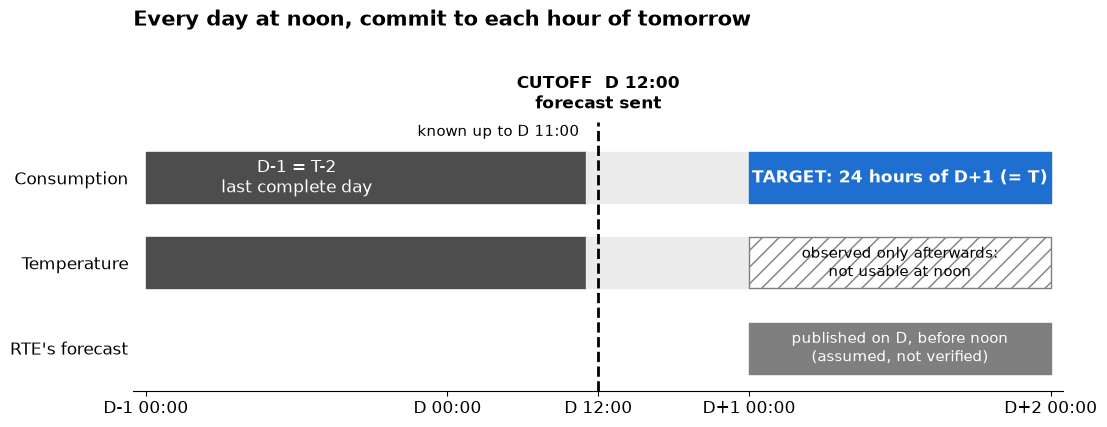

<details><summary>Technical details</summary>

- Cutoff: D at 12:00, Paris time. Consumption is known up to D 11:00 (the 11:00-12:00 hour is not complete yet).
- Target: the 24 hours of T = D+1, i.e. 12 to 36 hours ahead. The last complete day at the cutoff is T-2 = D-1,
  so the models use lags of 2 days or more, and the temperature of T-2 ("persistence").
- Temperature: the dataset holds the observed temperature, not a weather forecast. Using the temperature of D+1
  would assume a perfect weather forecast, so it is only shown as an upper bound (03_sarima, 04_lightgbm).
- RTE's forecast for D+1 is assumed to be published before 12:00 on D. This is not verified yet (risk 1, section 7).
- Metric: MAE (mean absolute error) in MW, on all hours, on the evening peak 18:00-21:00, and on the evening peak of
  cold days (daily mean temperature below 5 °C).

Source: README, Setup; 01_baseline to 05_final_model, section 1.

</details>

In [6]:
say("""Every day D, before noon, the trading desk buys tomorrow's electricity hour by hour, so it needs a forecast
of the 24 hours of D+1 made with what is known at noon: consumption up to 11:00 today, and only a weather
forecast for tomorrow, which our data does not have.""")

fig, ax = plt.subplots(figsize=(12, 4.2))
KNOWN, UNKNOWN = "#4d4d4d", "#ececec"
lanes = {"Consumption": 2, "Temperature": 1, "RTE's forecast": 0}
for lane in ("Consumption", "Temperature"):
    ax.broken_barh([(-24, 35)], (lanes[lane] - 0.3, 0.6), color=KNOWN)            # D-1 00:00 to D 11:00
    ax.broken_barh([(11, 13)], (lanes[lane] - 0.3, 0.6), color=UNKNOWN)           # rest of D
ax.broken_barh([(24, 24)], (lanes["Consumption"] - 0.3, 0.6), color=ACCENT)       # target: D+1
ax.broken_barh([(24, 24)], (lanes["Temperature"] - 0.3, 0.6), facecolor="white", edgecolor=RTE_GREY, hatch="//")
ax.broken_barh([(24, 24)], (lanes["RTE's forecast"] - 0.3, 0.6), color=RTE_GREY)

ax.text(-12, 2, "D-1 = T-2\nlast complete day", ha="center", va="center", color="white", fontsize=12)
ax.text(10.5, 2.45, "known up to D 11:00", ha="right", va="bottom", fontsize=11)
ax.text(36, 2, "TARGET: 24 hours of D+1 (= T)", ha="center", va="center", color="white", fontsize=12, weight="bold")
ax.text(36, 1, "observed only afterwards:\nnot usable at noon", ha="center", va="center", fontsize=11)
ax.text(36, 0, "published on D, before noon\n(assumed, not verified)", ha="center", va="center", color="white", fontsize=11)

ax.axvline(12, ymax=0.83, color="black", lw=2, ls="--")
ax.text(12, 2.75, "CUTOFF  D 12:00\nforecast sent", ha="center", va="bottom", fontsize=12, weight="bold")
ax.set_yticks(list(lanes.values()), list(lanes))
ax.set_xticks([-24, 0, 12, 24, 48], ["D-1 00:00", "D 00:00", "D 12:00", "D+1 00:00", "D+2 00:00"])
ax.set_xlim(-25, 49)
ax.set_ylim(-0.5, 3.3)
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("Every day at noon, commit to each hour of tomorrow", pad=30)
save(fig, "01_timeline")

details(
    """- Cutoff: D at 12:00, Paris time. Consumption is known up to D 11:00 (the 11:00-12:00 hour is not complete yet).
- Target: the 24 hours of T = D+1, i.e. 12 to 36 hours ahead. The last complete day at the cutoff is T-2 = D-1,
  so the models use lags of 2 days or more, and the temperature of T-2 ("persistence").
- Temperature: the dataset holds the observed temperature, not a weather forecast. Using the temperature of D+1
  would assume a perfect weather forecast, so it is only shown as an upper bound (03_sarima, 04_lightgbm).
- RTE's forecast for D+1 is assumed to be published before 12:00 on D. This is not verified yet (risk 1, section 7).
- Metric: MAE (mean absolute error) in MW, on all hours, on the evening peak 18:00-21:00, and on the evening peak of
  cold days (daily mean temperature below 5 °C).""",
    "README, Setup; 01_baseline to 05_final_model, section 1",
)

## 2. What we forecast: consumption follows the clock, the calendar, and above all the cold

Consumption has three rhythms: the day (low at night, peaks in the morning and evening), the week (weekends
10 % lower) and the year (winter 21 GW above summer). Above all, it rises with the cold:
about 2.1 GW more for each degree below 15 °C.

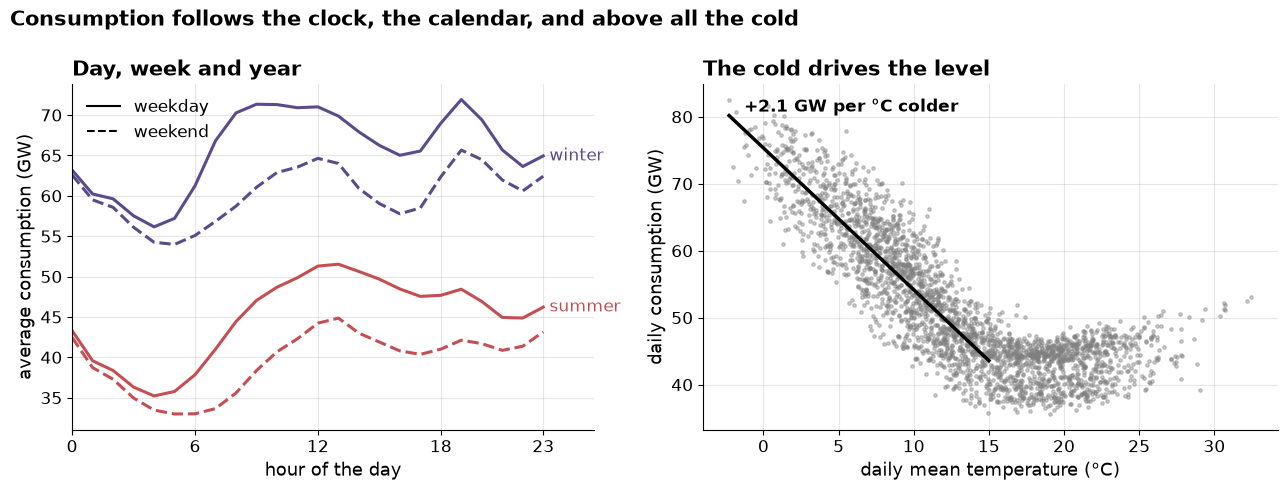

<details><summary>Technical details</summary>

- Data: hourly national consumption 2019-01-01 to 2026-06-30 (65,710 hours), mean by season
  (winter = Dec-Feb, summer = Jun-Aug), day type and local hour.
- Heating slope: linear fit of daily mean load on daily mean temperature for days below 15 °C:
  -2,117 MW/°C. Above about 15 °C the load is flat, with a small rise in heat waves.
- Season means: winter 64.1 GW, spring 49.3 GW, autumn 49.0 GW, summer 43.3 GW.
- These rhythms explain why naive forecasts (same hour a week ago) fail when the weather changes, see section 4.

Source: 00_eda.

</details>

In [7]:
profiles = (
    df.with_columns(pl.when(pl.col("weekday") >= 6).then(pl.lit("weekend")).otherwise(pl.lit("weekday")).alias("day_type"))
    .filter(pl.col("season").is_in(["winter", "summer"]))
    .group_by("season", "day_type", "hour").agg((pl.col("target").mean() / 1000).alias("gw"))
    .sort("hour")
)
days = (
    df.group_by("date").agg((pl.col("target").mean() / 1000).alias("gw"), pl.col("temperature_c").mean(), pl.col("season").first())
    .sort("date")
)
HEATING_C = 15  # below this daily temperature, consumption rises with the cold
slope, intercept = np.polyfit(*days.filter(pl.col("temperature_c") < HEATING_C).select("temperature_c", "gw").to_numpy().T, 1)
season_gw = dict(days.group_by("season").agg(pl.col("gw").mean()).iter_rows())
weekday_gw = dict(df.group_by(pl.col("weekday") >= 6).agg(pl.col("target").mean() / 1000).iter_rows())

say(f"""Consumption has three rhythms: the day (low at night, peaks in the morning and evening), the week (weekends
{100 * (1 - weekday_gw[True] / weekday_gw[False]):.0f} % lower) and the year (winter {season_gw["winter"] - season_gw["summer"]:.0f} GW above summer). Above all, it rises with the cold:
about {-slope:.1f} GW more for each degree below {HEATING_C} °C.""")

SEASON_COLORS = {"winter": "#5b4b8a", "summer": "#c44e52"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.1]})
for (season, day_type), part in profiles.group_by("season", "day_type", maintain_order=True):
    ax1.plot(part["hour"], part["gw"], color=SEASON_COLORS[season], lw=2.2, ls="-" if day_type == "weekday" else "--")
    if day_type == "weekday":
        ax1.text(23.3, part["gw"][-1], season, color=SEASON_COLORS[season], va="center", fontsize=12)
ax1.plot([], [], color="k", ls="-", label="weekday")
ax1.plot([], [], color="k", ls="--", label="weekend")
ax1.legend(loc="upper left")
ax1.set_xticks([0, 6, 12, 18, 23])
ax1.set_xlim(0, 25.5)
ax1.set_xlabel("hour of the day")
ax1.set_ylabel("average consumption (GW)")
ax1.set_title("Day, week and year")

ax2.scatter(days["temperature_c"], days["gw"], s=6, color=RTE_GREY, alpha=0.4)
xs = np.array([days["temperature_c"].min(), HEATING_C])
ax2.plot(xs, intercept + slope * xs, color="black", lw=2.5)
ax2.text(xs[0] + 1, intercept + slope * xs[0], f"+{-slope:.1f} GW per °C colder", fontsize=12, va="bottom", weight="bold")
ax2.set_xlabel("daily mean temperature (°C)")
ax2.set_ylabel("daily consumption (GW)")
ax2.set_title("The cold drives the level")
fig.suptitle("Consumption follows the clock, the calendar, and above all the cold", x=0.01, ha="left", fontsize=15, weight="bold")
fig.tight_layout()
save(fig, "02_seasonality")

details(
    f"""- Data: hourly national consumption {df["date"].min()} to {df["date"].max()} ({df.height:,} hours), mean by season
  (winter = Dec-Feb, summer = Jun-Aug), day type and local hour.
- Heating slope: linear fit of daily mean load on daily mean temperature for days below {HEATING_C} °C:
  {slope * 1000:,.0f} MW/°C. Above about {HEATING_C} °C the load is flat, with a small rise in heat waves.
- Season means: {", ".join(f"{s} {v:.1f} GW" for s, v in sorted(season_gw.items(), key=lambda kv: -kv[1]))}.
- These rhythms explain why naive forecasts (same hour a week ago) fail when the weather changes, see section 4.""",
    "00_eda",
)

## 3. The benchmark: RTE is good but too low, by an amount that depends on the hour

RTE's forecast is accurate (its error is 2.9 % of consumption on average), but since 2023 it has been
too low by about 1.1 GW, and on the test year it is too low at 21 hours of the day out of 24.

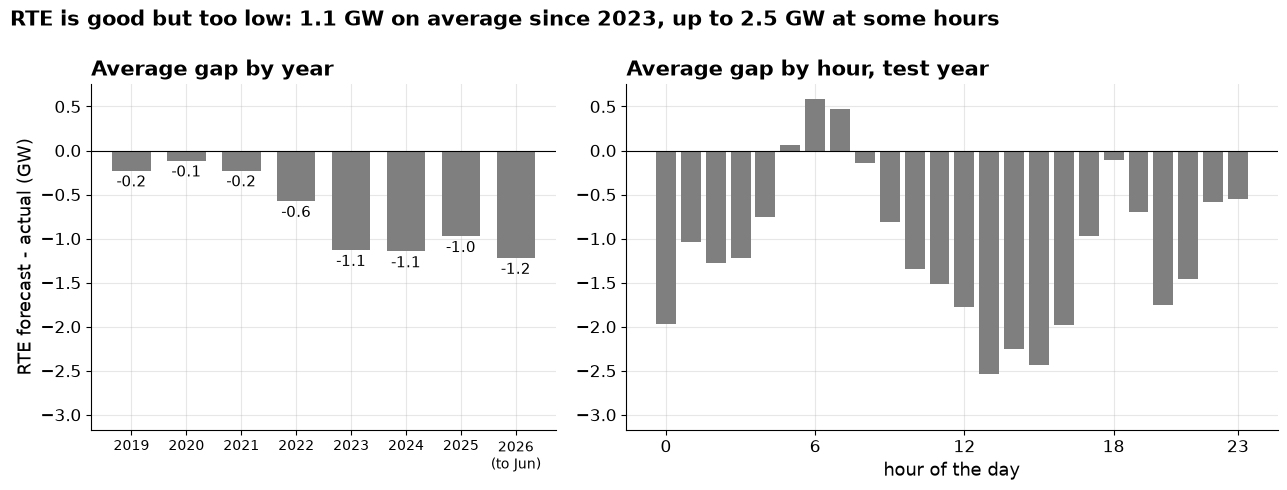

<details><summary>Technical details</summary>

- Bias = mean of (RTE's D-1 forecast - actual load). Negative = RTE too low.
- By year (MW): 2019 -228, 2020 -115, 2021 -227, 2022 -574, 2023 -1,131, 2024 -1,146, 2025 -973, 2026 -1,220.
  Mean since 2023: -1,103 MW.
- By hour on the test year (Jul 2025 to Jun 2026): from -2,536 MW (hour 13) to
  582 MW (hour 6).
- RTE raw on the test: MAE 1,439 MW, RMSE 1,783 MW, MAPE 2.86 %, bias -1,086 MW.
- Because the bias is stable and depends on the hour, it can be learnt (LightGBM residual) or simply removed
  (hourly debiasing rule), see section 4.

Source: 00_eda (RTE's error), 05_final_model A.3 (bias on the test).

</details>

In [8]:
RECENT = "test year (Jul 2025 to Jun 2026)"
bias_year = (
    df.drop_nulls("rte_forecast_j1_mw")
    .group_by(pl.col("date").dt.year().alias("year"))
    .agg(((pl.col("rte_forecast_j1_mw") - pl.col("target")).mean() / 1000).alias("bias_gw"), pl.col("date").max().alias("last"))
    .sort("year")
)
rte_col = FORECASTS["RTE raw"]
bias_hour = (
    test.drop_nulls(rte_col).group_by("hour")
    .agg(((pl.col(rte_col) - pl.col("target")).mean() / 1000).alias("bias_gw")).sort("hour")
)
since_2023 = df.filter(pl.col("date") >= date(2023, 1, 1)).drop_nulls("rte_forecast_j1_mw")
bias_2023 = (since_2023["rte_forecast_j1_mw"] - since_2023["target"]).mean()
rte_test = compute_metrics(test, rte_col)
n_low = (bias_hour["bias_gw"] < 0).sum()

say(f"""RTE's forecast is accurate (its error is {rte_test["MAPE"]:.1f} % of consumption on average), but since 2023 it has been
too low by about {gw(-bias_2023, 1)}, and on the test year it is too low at {n_low} hours of the day out of 24.""")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.4]})
labels = [f"{y}" if last.month == 12 else f"{y}\n(to {last:%b})" for y, last in bias_year.select("year", "last").iter_rows()]
bars = ax1.bar(labels, bias_year["bias_gw"], color=RTE_GREY, width=0.7)
ax1.bar_label(bars, fmt="%.1f", padding=3, fontsize=11)
ax1.axhline(0, color="black", lw=0.8)
ax1.set_ylabel("RTE forecast - actual (GW)")
ax1.set_title("Average gap by year")
ax1.tick_params(axis="x", labelsize=10)
ax2.bar(bias_hour["hour"], bias_hour["bias_gw"], color=RTE_GREY, width=0.8)
ax2.axhline(0, color="black", lw=0.8)
ax2.set_xticks([0, 6, 12, 18, 23])
ax2.set_xlabel("hour of the day")
ax2.set_title("Average gap by hour, test year")
for ax in (ax1, ax2):
    ax.set_ylim(min(bias_year["bias_gw"].min(), bias_hour["bias_gw"].min()) * 1.25, max(0.3, bias_hour["bias_gw"].max() * 1.3))
fig.suptitle(f"RTE is good but too low: {gw(-bias_2023, 1)} on average since 2023, up to {gw(-bias_hour['bias_gw'].min() * 1000, 1)} at some hours", x=0.01, ha="left", fontsize=15, weight="bold")
fig.tight_layout()
save(fig, "03_rte_bias")

details(
    f"""- Bias = mean of (RTE's D-1 forecast - actual load). Negative = RTE too low.
- By year (MW): {", ".join(f"{y} {b * 1000:,.0f}" for y, b in bias_year.select("year", "bias_gw").iter_rows())}.
  Mean since 2023: {mw(bias_2023)}.
- By hour on the {RECENT}: from {mw(bias_hour["bias_gw"].min() * 1000)} (hour {bias_hour.sort("bias_gw")["hour"][0]}) to
  {mw(bias_hour["bias_gw"].max() * 1000)} (hour {bias_hour.sort("bias_gw")["hour"][-1]}).
- RTE raw on the test: MAE {mw(rte_test["MAE"])}, RMSE {mw(rte_test["RMSE"])}, MAPE {rte_test["MAPE"]:.2f} %, bias {mw(rte_test["bias"])}.
- Because the bias is stable and depends on the hour, it can be learnt (LightGBM residual) or simply removed
  (hourly debiasing rule), see section 4.""",
    "00_eda (RTE's error), 05_final_model A.3 (bias on the test)",
)

## 4. Our path: we don't beat RTE without it, we beat it by correcting it

Our best model without RTE's forecast stays 40 % worse than RTE. Starting from RTE's forecast and
removing its usual error cuts the error by 37 % (LightGBM residual) to 43 % (RTE debiased by hour).

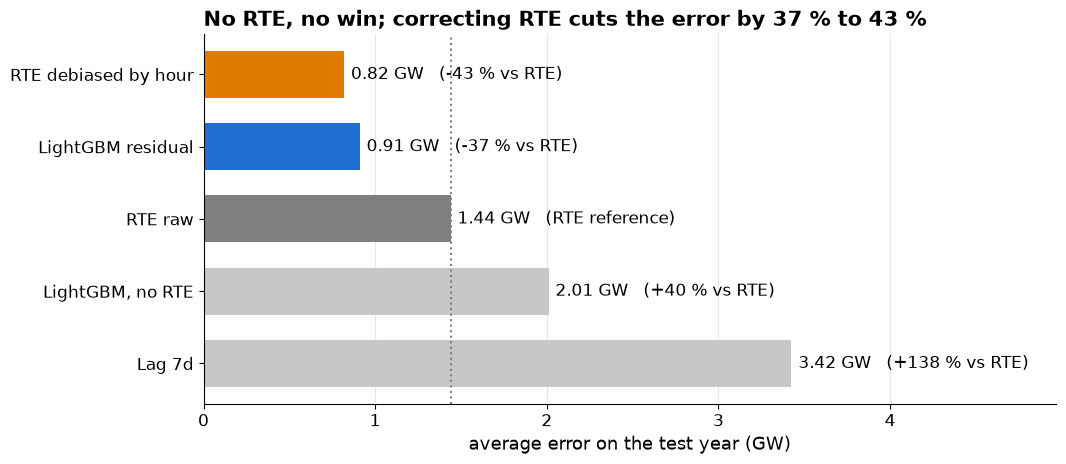

<details><summary>Technical details</summary>

Hourly forecasts, MAE (MW) on the test year:

| forecast | global | evening_peak_18-20h | evening_peak_cold_days | vs_reference_(%) |
|---|---|---|---|---|
| Lag 7d | 3,425 MW | 3,612 MW | 9,225 MW | 138.0 |
| LightGBM, no RTE | 2,010 MW | 2,036 MW | 4,466 MW | 39.7 |
| RTE raw | 1,439 MW | 1,348 MW | 2,307 MW | 0.0 |
| LightGBM residual | 910 MW | 987 MW | 1,906 MW | -36.8 |
| RTE debiased by hour | 819 MW | 943 MW | 1,528 MW | -43.1 |

- Lag 7d: the load of the same hour 7 days before (01_baseline). LightGBM, no RTE: gradient boosting on calendar,
  lags of 2 days or more and T-2 temperature (04_lightgbm). LightGBM residual: predicts load - RTE, forecast = RTE +
  correction (05_final_model). RTE debiased by hour: RTE minus its mean error at the same hour over T-29 to T-2
  (extension_rte_debiased).
- Daily models (02_ar, 03_sarima) forecast the daily mean, so their MAE (GW, daily) is not comparable with the
  hourly ones. None of them beats RTE:

| forecast | daily MAE (GW) | vs_reference_(%) |
|---|---|---|
| RTE_raw | 1.16 | 0.0 |
| SARIMAX_observed_temp._(upper_bound) | 1.16 | 0.2 |
| SARIMAX_persistence | 1.65 | 42.5 |
| AR(8)_+_normal | 1.69 | 46.3 |
| SARIMA | 1.79 | 54.7 |
| Holt-Winters | 1.83 | 58.1 |
| Normal_only | 2.66 | 129.9 |
| Seasonal_naive_(T-7) | 3.29 | 185.1 |

Source: 06_comparison; 01_baseline, 04_lightgbm, 05_final_model, extension_rte_debiased.

</details>

In [9]:
ladder = sorted(FORECASTS, key=lambda name: -mae[name]["global"])
say(f"""Our best model without RTE's forecast stays {-gain["LightGBM, no RTE"]:.0f} % worse than RTE. Starting from RTE's forecast and
removing its usual error cuts the error by {gain[FINAL]:.0f} % ({FINAL}) to {gain[CANDIDATE]:.0f} % ({CANDIDATE}).""")

fig, ax = plt.subplots(figsize=(11, 4.8))
values = [mae[name]["global"] / 1000 for name in ladder]
bars = ax.barh(ladder, values, color=[COLORS[name] for name in ladder], height=0.65)
for bar, name in zip(bars, ladder):
    vs = "RTE reference" if name == "RTE raw" else f"{-gain[name]:+.0f} % vs RTE"
    ax.text(bar.get_width() + 0.04, bar.get_y() + bar.get_height() / 2, f"{bar.get_width():.2f} GW   ({vs})", va="center", fontsize=12)
ax.axvline(mae["RTE raw"]["global"] / 1000, color=RTE_GREY, ls=":", lw=1.5)
ax.set_xlim(0, max(values) * 1.45)
ax.set_xlabel("average error on the test year (GW)")
ax.grid(axis="y", visible=False)
ax.set_title(f"No RTE, no win; correcting RTE cuts the error by {gain[FINAL]:.0f} % to {gain[CANDIDATE]:.0f} %")
save(fig, "04_model_ladder")

daily = load_predictions(["02_ar", "03_sarima"], keys=DAILY_KEYS)
daily_names = [c for c in daily.columns if c not in DAILY_KEYS]
daily_score = scorecard_daily(daily, {name: name for name in daily_names}, reference="RTE_raw").sort("MAE")
details(
    f"""Hourly forecasts, MAE (MW) on the test year:

{md_table(score.sort("global", descending=True).with_columns(pl.col("global", "evening_peak_18-20h", "evening_peak_cold_days").map_elements(mw, return_dtype=pl.String)))}

- Lag 7d: the load of the same hour 7 days before (01_baseline). LightGBM, no RTE: gradient boosting on calendar,
  lags of 2 days or more and T-2 temperature (04_lightgbm). LightGBM residual: predicts load - RTE, forecast = RTE +
  correction (05_final_model). RTE debiased by hour: RTE minus its mean error at the same hour over T-29 to T-2
  (extension_rte_debiased).
- Daily models (02_ar, 03_sarima) forecast the daily mean, so their MAE (GW, daily) is not comparable with the
  hourly ones. None of them beats RTE:

{md_table(daily_score.select("forecast", pl.col("MAE").alias("daily MAE (GW)"), "vs_reference_(%)"))}""",
    "06_comparison; 01_baseline, 04_lightgbm, 05_final_model, extension_rte_debiased",
)

## 5. Q1. Can we beat RTE? Yes, at every hour type, including cold evenings

Yes. Both corrected forecasts beat RTE on all hours, on the evening peak and on the cold evening peaks that
cost the most: 17 % lower error there for our model, 34 % for the correction rule.

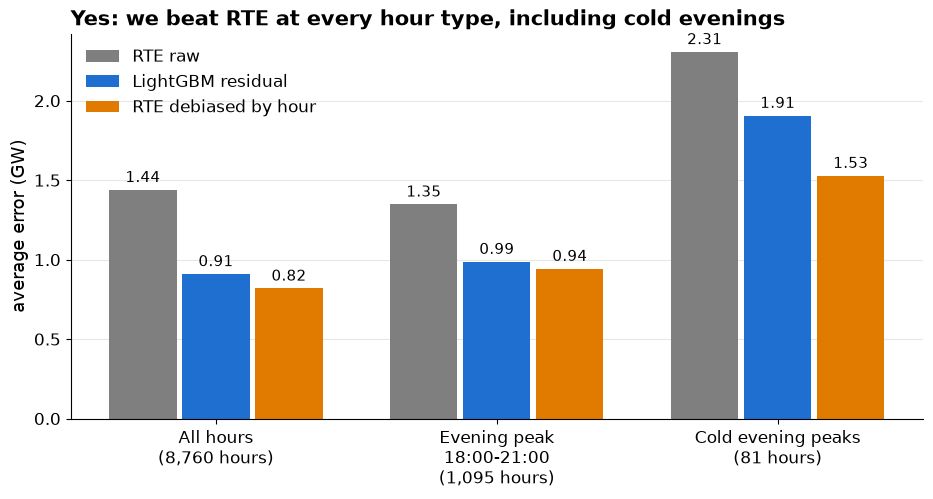

<details><summary>Technical details</summary>

MAE (MW) and gap to RTE raw by scope:

| forecast | All hours | Evening peak 18:00-21:00 | Cold evening peaks |
|---|---|---|---|
| RTE raw | 1,439 MW (+0.0 %) | 1,348 MW (+0.0 %) | 2,307 MW (+0.0 %) |
| LightGBM residual | 910 MW (-36.8 %) | 987 MW (-26.8 %) | 1,906 MW (-17.4 %) |
| RTE debiased by hour | 819 MW (-43.1 %) | 943 MW (-30.0 %) | 1,528 MW (-33.8 %) |

- Cold day = daily mean of the observed temperature below 5 °C (known only afterwards, used for evaluation only).
  The cold evening peak scope has only 81 hours, so its MAE is noisy.
- Choices were made on 4 quarterly walk-forward folds (Jul 2024 to Jun 2025), not on the test. On the folds the
  hourly rule also comes first: 830 MW vs 860 MW for the LightGBM residual (see extension_rte_debiased, section 3).

Source: 05_final_model section 3, extension_rte_debiased sections 3 and 4.

</details>

In [10]:
SCOPES = {"global": "All hours", "evening_peak_18-20h": "Evening peak\n18:00-21:00", "evening_peak_cold_days": "Cold evening peaks"}
hours = {"global": test.height, "evening_peak_18-20h": test.filter(PEAK).height, "evening_peak_cold_days": test.filter(PEAK & COLD_DAY).height}

say(f"""Yes. Both corrected forecasts beat RTE on all hours, on the evening peak and on the cold evening peaks that
cost the most: {cold_gain[FINAL]:.0f} % lower error there for our model, {cold_gain[CANDIDATE]:.0f} % for the correction rule.""")

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(SCOPES))
w = 0.26
for i, name in enumerate(KPI):
    bars = ax.bar(x + (i - 1) * w, [mae[name][s] / 1000 for s in SCOPES], w * 0.92, color=COLORS[name], label=name)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=11)
ax.set_xticks(x, [f"{label}\n({hours[s]:,} hours)" for s, label in SCOPES.items()])
ax.set_ylabel("average error (GW)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
ax.set_title("Yes: we beat RTE at every hour type, including cold evenings")
save(fig, "05_q1_beat_rte")

details(
    f"""MAE (MW) and gap to RTE raw by scope:

{md_table(pl.DataFrame([{"forecast": name, **{SCOPES[s].replace(chr(10), " "): f"{mw(mae[name][s])} ({100 * (mae[name][s] / mae['RTE raw'][s] - 1):+.1f} %)" for s in SCOPES}} for name in KPI]))}

- Cold day = daily mean of the observed temperature below {COLD_DAY_C:.0f} °C (known only afterwards, used for evaluation only).
  The cold evening peak scope has only {hours["evening_peak_cold_days"]} hours, so its MAE is noisy.
- Choices were made on 4 quarterly walk-forward folds (Jul 2024 to Jun 2025), not on the test. On the folds the
  hourly rule also comes first: 830 MW vs 860 MW for the LightGBM residual (see extension_rte_debiased, section 3).""",
    "05_final_model section 3, extension_rte_debiased sections 3 and 4",
)

## 6. Q2. How uncertain, and when does it fail? The band is right on average, too narrow in the cold

### 6.1 On a cold week, the model follows the peaks but misses the same days as RTE

In the cold week of 5 to 11 January 2026, our model reaches the peaks (highest hour 90.0 GW for an actual
90.2 GW) and the actual load stays inside the 80 % band 61 % of the time. It still misses whole days
when RTE does, such as Monday 5 January and Thursday 8 January.

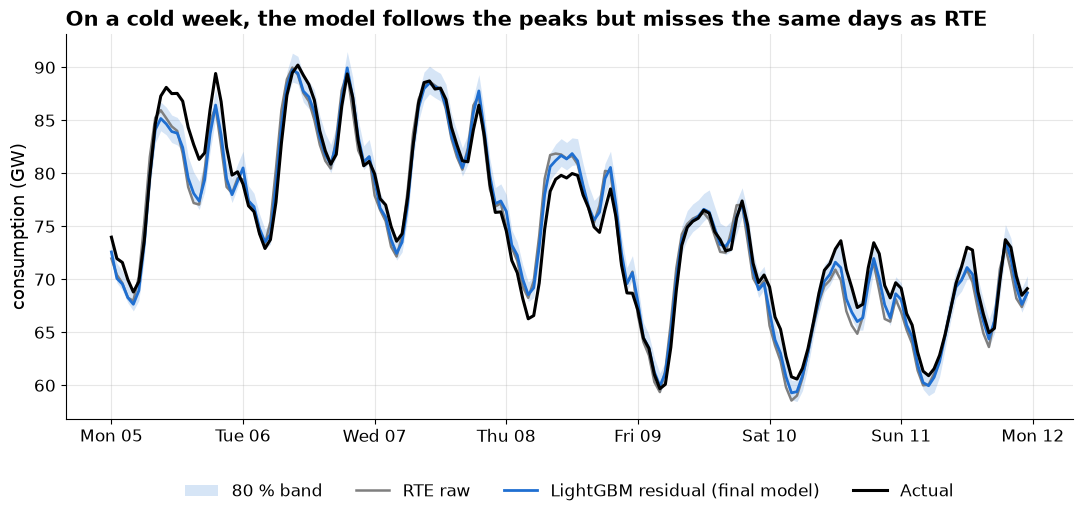

<details><summary>Technical details</summary>

- MAE over the week: RTE raw 1,506 MW, LightGBM residual 1,211 MW. Highest hour: actual 90,210 MW,
  final model 89,951 MW, RTE raw 89,975 MW.
- Worst days of the week for the final model (daily MAE, bias): 2026-01-05 2,381 MW, -2,381 MW; 2026-01-08 1,787 MW, 1,787 MW.
- On the 15 worst days of the test year, the final model and RTE err in the same direction (05_final_model A.6):
  Christmas week, holidays, cold days, some weekends. The model removes RTE's usual error, not its error of the day.

Source: 05_final_model section 4 and A.5, A.6.

</details>

In [11]:
WEEK = (date(2026, 1, 5), date(2026, 1, 11))
final_col = FORECASTS[FINAL]
week = test.filter(pl.col("date").is_between(*WEEK))
week_mae = {name: compute_metrics(week, FORECASTS[name])["MAE"] for name in ["RTE raw", FINAL]}
week_inside = 100 * week["target"].is_between(week["lo80"], week["hi80"]).mean()
worst_days = (
    week.group_by("date").agg((pl.col(final_col) - pl.col("target")).abs().mean().alias("mae"), (pl.col(final_col) - pl.col("target")).mean().alias("bias"))
    .sort("mae", descending=True).head(2)
)

say(f"""In the cold week of 5 to 11 January 2026, our model reaches the peaks (highest hour {week[final_col].max() / 1000:.1f} GW for an actual
{week["target"].max() / 1000:.1f} GW) and the actual load stays inside the 80 % band {week_inside:.0f} % of the time. It still misses whole days
when RTE does, such as {" and ".join(f"{d:%A} {d.day} {d:%B}" for d in worst_days["date"].sort())}.""")

fig, ax = plt.subplots(figsize=(13, 5))
t = week["datetime_fr"]
ax.fill_between(t, week["lo80"] / 1000, week["hi80"] / 1000, color=ACCENT, alpha=0.18, lw=0, label="80 % band")
ax.plot(t, week[FORECASTS["RTE raw"]] / 1000, color=RTE_GREY, lw=1.8, label="RTE raw")
ax.plot(t, week[final_col] / 1000, color=ACCENT, lw=2, label=f"{FINAL} (final model)")
ax.plot(t, week["target"] / 1000, color=ACTUAL, lw=2.2, label="Actual")
ax.xaxis.set_major_locator(mdates.DayLocator(tz=t.dtype.time_zone))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d", tz=t.dtype.time_zone))
ax.set_ylabel("consumption (GW)")
ax.legend(loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.25))
ax.set_title("On a cold week, the model follows the peaks but misses the same days as RTE")
save(fig, "06a_cold_week")

details(
    f"""- MAE over the week: RTE raw {mw(week_mae["RTE raw"])}, {FINAL} {mw(week_mae[FINAL])}. Highest hour: actual {mw(week["target"].max())},
  final model {mw(week[final_col].max())}, RTE raw {mw(week[FORECASTS["RTE raw"]].max())}.
- Worst days of the week for the final model (daily MAE, bias): {"; ".join(f"{d} {mw(m)}, {mw(b)}" for d, m, b in worst_days.iter_rows())}.
- On the 15 worst days of the test year, the final model and RTE err in the same direction (05_final_model A.6):
  Christmas week, holidays, cold days, some weekends. The model removes RTE's usual error, not its error of the day.""",
    "05_final_model section 4 and A.5, A.6",
)

### 6.2 The 80 % band holds in summer and autumn, but is too narrow in the cold

Our 80 % band is about 2.4 GW wide. It contains the actual load 76 % of the time over the year, close to the
promised 80 %, but only 61 % in winter and 51 % on cold evening peaks: it must be wider on cold days.

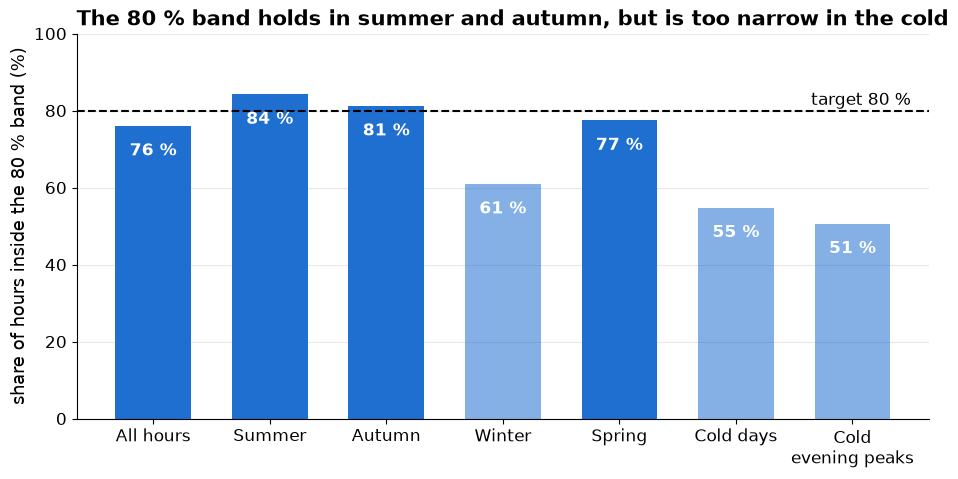

<details><summary>Technical details</summary>

Split conformal intervals: per-hour quantiles of the validation errors of the final model (10-90 % for the 80 %
band, 2.5-97.5 % for 95 %). Coverage = share of test hours where the actual load is inside the band.

| scope | hours | coverage_80_% | width_80_(MW) | coverage_95_% | width_95_(MW) |
|---|---|---|---|---|---|
| All hours | 8759 | 76.0 | 2,378 MW | 94.0 | 4,244 MW |
| Summer | 2208 | 84.0 | 2,378 MW | 97.0 | 4,244 MW |
| Autumn | 2184 | 81.0 | 2,378 MW | 96.0 | 4,244 MW |
| Winter | 2160 | 61.0 | 2,378 MW | 88.0 | 4,244 MW |
| Spring | 2207 | 77.0 | 2,378 MW | 96.0 | 4,244 MW |
| Cold days | 648 | 55.0 | 2,378 MW | 82.0 | 4,244 MW |
| Cold evening peaks | 81 | 51.0 | 2,748 MW | 73.0 | 4,608 MW |

- The width depends only on the hour, not on season or temperature, so the band is narrowest where errors cost most.
- Conditioning on "cold at the cutoff" (T-2 below 5 °C) only helps a little, see 05_final_model A.4.

Source: 05_final_model, Prediction intervals and A.2, A.4; intervals read from data/predictions/05_intervals.csv.

</details>

In [12]:
say(f"""Our 80 % band is about {gw(cov["All hours"]["width_80_(MW)"], 1)} wide. It contains the actual load {cov["All hours"]["coverage_80_%"]:.0f} % of the time over the year, close to the
promised 80 %, but only {cov["Winter"]["coverage_80_%"]:.0f} % in winter and {cov["Cold evening peaks"]["coverage_80_%"]:.0f} % on cold evening peaks: it must be wider on cold days.""")

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar([s.replace(" evening", "\nevening") for s in coverage["scope"]], coverage["coverage_80_%"], color=ACCENT, width=0.65)
for bar, scope in zip(bars, coverage["scope"]):
    if scope in ("Winter", "Cold days", "Cold evening peaks"):
        bar.set_alpha(0.55)
ax.bar_label(bars, fmt="%.0f %%", padding=-24, color="white", fontsize=12, weight="bold")
ax.axhline(80, color="black", ls="--", lw=1.5)
ax.text(len(coverage) - 0.5, 81.5, "target 80 %", ha="right", fontsize=12)
ax.set_ylim(0, 100)
ax.set_ylabel("share of hours inside the 80 % band (%)")
ax.grid(axis="x", visible=False)
ax.set_title("The 80 % band holds in summer and autumn, but is too narrow in the cold")
save(fig, "06b_interval_coverage")

details(
    f"""Split conformal intervals: per-hour quantiles of the validation errors of the final model (10-90 % for the 80 %
band, 2.5-97.5 % for 95 %). Coverage = share of test hours where the actual load is inside the band.

{md_table(coverage.with_columns(pl.col("coverage_80_%", "coverage_95_%").round(0), pl.col("width_80_(MW)", "width_95_(MW)").map_elements(mw, return_dtype=pl.String)))}

- The width depends only on the hour, not on season or temperature, so the band is narrowest where errors cost most.
- Conditioning on "cold at the cutoff" (T-2 below {COLD_DAY_C:.0f} °C) only helps a little, see 05_final_model A.4.""",
    "05_final_model, Prediction intervals and A.2, A.4; intervals read from data/predictions/05_intervals.csv",
)

### 6.3 Errors grow in the cold, but the model beats RTE at every temperature

Our model is better than RTE at every temperature, but its error is about 1.9 times larger on days below
5 °C than on mild days (10 to 20 °C), and these cold days are rare (27 days in the test year).

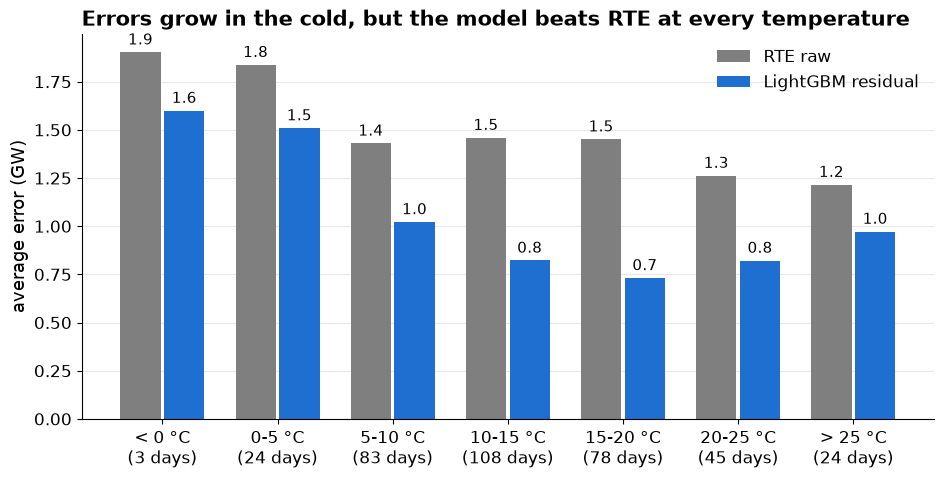

<details><summary>Technical details</summary>

Mean of the daily MAE by bin of daily mean temperature (MW):

| temp_bin | days | RTE raw | LightGBM residual |
|---|---|---|---|
| < 0 | 3 | 1,903 MW | 1,600 MW |
| 0-5 | 24 | 1,838 MW | 1,509 MW |
| 5-10 | 83 | 1,430 MW | 1,022 MW |
| 10-15 | 108 | 1,459 MW | 822 MW |
| 15-20 | 78 | 1,451 MW | 732 MW |
| 20-25 | 45 | 1,262 MW | 822 MW |
| > 25 | 24 | 1,215 MW | 972 MW |

- Only 3 test days below 0 °C: extreme cold is barely seen, in training as in the test.

Source: 05_final_model A.7.

</details>

In [13]:
TEMP_LABELS = ["< 0", "0-5", "5-10", "10-15", "15-20", "20-25", "> 25"]
by_temp = (
    test.group_by("date").agg(
        pl.col("daily_temp").first(),
        *[(pl.col(FORECASTS[name]) - pl.col("target")).abs().mean().alias(name) for name in ["RTE raw", FINAL]],
    )
    .with_columns(pl.col("daily_temp").bin_intervals([0, 5, 10, 15, 20, 25], labels=TEMP_LABELS).alias("temp_bin"))
    .group_by("temp_bin").agg(pl.len().alias("days"), pl.col("RTE raw", FINAL).mean())
    .sort("temp_bin")
)
cold_bins = by_temp.filter(pl.col("temp_bin").is_in(["< 0", "0-5"]))
mild_bins = by_temp.filter(pl.col("temp_bin").is_in(["10-15", "15-20"]))
cold_ratio = (cold_bins[FINAL] * cold_bins["days"]).sum() / cold_bins["days"].sum() / ((mild_bins[FINAL] * mild_bins["days"]).sum() / mild_bins["days"].sum())

say(f"""Our model is better than RTE at every temperature, but its error is about {cold_ratio:.1f} times larger on days below
{COLD_DAY_C:.0f} °C than on mild days (10 to 20 °C), and these cold days are rare ({cold_bins["days"].sum()} days in the test year).""")

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(by_temp.height)
w = 0.38
for i, name in enumerate(["RTE raw", FINAL]):
    bars = ax.bar(x + (i - 0.5) * w, by_temp[name] / 1000, w * 0.92, color=COLORS[name], label=name)
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=11)
ax.set_xticks(x, [f"{b} °C\n({n} days)" for b, n in by_temp.select("temp_bin", "days").iter_rows()])
ax.set_ylabel("average error (GW)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_title("Errors grow in the cold, but the model beats RTE at every temperature")
save(fig, "06c_error_by_temperature")

details(
    f"""Mean of the daily MAE by bin of daily mean temperature (MW):

{md_table(by_temp.with_columns(pl.col("temp_bin").cast(pl.String), pl.col("RTE raw", FINAL).map_elements(mw, return_dtype=pl.String)))}

- Only {by_temp.filter(pl.col("temp_bin") == "< 0")["days"].sum()} test days below 0 °C: extreme cold is barely seen, in training as in the test.""",
    "05_final_model A.7",
)

## 7. Q3. What to deploy: our model now, the correction rule validated alongside it

Deploy our model (LightGBM residual, notebook 05): it is chosen by a rule fixed before the test and it comes with an
uncertainty band. Run the hourly correction rule alongside it as a candidate: it is simpler and better on average
(0.82 GW vs 0.91 GW), and it beats our model in 10 months out of 12, but it has no uncertainty band and was added after the selection rule of 05.

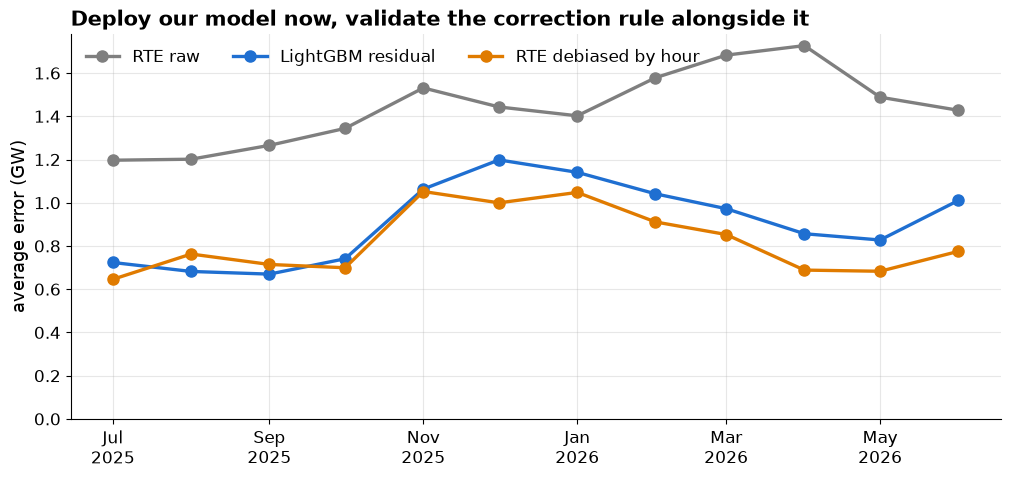

| Risk | Impact | Mitigation |
|---|---|---|
| RTE's forecast arrives after noon (assumed, not verified) | Both corrected forecasts need it: no forecast on time | Check RTE's publication calendar; fall back to our model without RTE (2.01 GW) |
| RTE's bias changes suddenly | The correction lags: about a month for the rule, until retraining for our model | Monitor the 7-day bias, alert beyond ±0.5 GW, retrain regularly |
| Live data differ from the clean data we tested on | Live error higher than the 0.91 GW measured | Replay the model on archived real-time data before go-live |
| Extreme cold and unusual holidays | Worst days; the 80 % band only holds 51 % of cold evening peaks | Manual override and a wider safety margin on cold days and around holidays |

<details><summary>Technical details</summary>

- Monthly MAE (MW):

| month | RTE raw | LightGBM residual | RTE debiased by hour |
|---|---|---|---|
| 2025-07 | 1,197 MW | 724 MW | 646 MW |
| 2025-08 | 1,201 MW | 682 MW | 763 MW |
| 2025-09 | 1,265 MW | 670 MW | 715 MW |
| 2025-10 | 1,344 MW | 741 MW | 699 MW |
| 2025-11 | 1,531 MW | 1,063 MW | 1,052 MW |
| 2025-12 | 1,443 MW | 1,198 MW | 1,000 MW |
| 2026-01 | 1,402 MW | 1,141 MW | 1,048 MW |
| 2026-02 | 1,578 MW | 1,041 MW | 911 MW |
| 2026-03 | 1,683 MW | 973 MW | 853 MW |
| 2026-04 | 1,727 MW | 857 MW | 688 MW |
| 2026-05 | 1,488 MW | 828 MW | 683 MW |
| 2026-06 | 1,428 MW | 1,010 MW | 775 MW |

- Why 05 and not the rule as final model: the selection rule of 05 (best mean MAE on the folds, cold evening peaks
  as tie-break) picks among the LightGBM models. The rule came later, as an extension; it is better on the folds
  (830 vs 860 MW, see extension_rte_debiased, section 3) and on the test (819 MW vs 910 MW), but has no prediction intervals.
- Fallbacks: RTE raw (1,439 MW) if our model breaks, LightGBM without RTE (2,010 MW) if RTE is late.
- The rule uses a 28-day window (T-29 to T-2), hence about a month to follow a change of RTE's bias.
- Consolidated vs real-time: at 12:00 only the real-time vintage exists and recent lags can be revised.

Source: 05_final_model A.9, README Answers, extension_rte_debiased section 5.

</details>

In [14]:
monthly = (
    test.group_by(pl.col("date").dt.truncate("1mo").alias("month"))
    .agg(*[(pl.col(FORECASTS[name]) - pl.col("target")).abs().mean().alias(name) for name in KPI])
    .sort("month")
)
rule_wins = (monthly[CANDIDATE] < monthly[FINAL]).sum()

say(f"""Deploy our model ({FINAL}, notebook 05): it is chosen by a rule fixed before the test and it comes with an
uncertainty band. Run the hourly correction rule alongside it as a candidate: it is simpler and better on average
({gw(mae[CANDIDATE]["global"])} vs {gw(mae[FINAL]["global"])}), and it beats our model in {rule_wins} months out of {monthly.height}, but it has no uncertainty band and was added after the selection rule of 05.""")

fig, ax = plt.subplots(figsize=(12, 5))
for name in KPI:
    ax.plot(monthly["month"], monthly[name] / 1000, color=COLORS[name], lw=2.4, marker="o", ms=8, label=name)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_ylim(0)
ax.set_ylabel("average error (GW)")
ax.legend(loc="upper left", ncol=3)
ax.set_title("Deploy our model now, validate the correction rule alongside it")
save(fig, "07_monthly_error")

say(md_table(pl.DataFrame({
    "Risk": [
        "RTE's forecast arrives after noon (assumed, not verified)",
        "RTE's bias changes suddenly",
        "Live data differ from the clean data we tested on",
        "Extreme cold and unusual holidays",
    ],
    "Impact": [
        "Both corrected forecasts need it: no forecast on time",
        "The correction lags: about a month for the rule, until retraining for our model",
        f"Live error higher than the {gw(mae[FINAL]['global'])} measured",
        f"Worst days; the 80 % band only holds {cov['Cold evening peaks']['coverage_80_%']:.0f} % of cold evening peaks",
    ],
    "Mitigation": [
        f"Check RTE's publication calendar; fall back to our model without RTE ({gw(mae['LightGBM, no RTE']['global'])})",
        "Monitor the 7-day bias, alert beyond ±0.5 GW, retrain regularly",
        "Replay the model on archived real-time data before go-live",
        "Manual override and a wider safety margin on cold days and around holidays",
    ],
})))

details(
    f"""- Monthly MAE (MW):

{md_table(monthly.with_columns(pl.col("month").dt.strftime("%Y-%m"), pl.col(*KPI).map_elements(mw, return_dtype=pl.String)))}

- Why 05 and not the rule as final model: the selection rule of 05 (best mean MAE on the folds, cold evening peaks
  as tie-break) picks among the LightGBM models. The rule came later, as an extension; it is better on the folds
  (830 vs 860 MW, see extension_rte_debiased, section 3) and on the test ({mw(mae[CANDIDATE]["global"])} vs {mw(mae[FINAL]["global"])}), but has no prediction intervals.
- Fallbacks: RTE raw ({mw(mae["RTE raw"]["global"])}) if our model breaks, LightGBM without RTE ({mw(mae["LightGBM, no RTE"]["global"])}) if RTE is late.
- The rule uses a 28-day window (T-29 to T-2), hence about a month to follow a change of RTE's bias.
- Consolidated vs real-time: at 12:00 only the real-time vintage exists and recent lags can be revised.""",
    "05_final_model A.9, README Answers, extension_rte_debiased section 5",
)

## 8. Appendix

### 8.1 All hourly forecasts on the test year (table of 06_comparison)

In [15]:
EXTRA = ["date", "hour", "temperature_c", "daily_temp", "season", "lo80", "hi80", "lo95", "hi95"]
all_cols = [c for c in test.columns if c not in HOURLY_KEYS + EXTRA]
scorecard(test, {c: c for c in all_cols}, reference="RTE_raw").sort("global")

forecast,global,evening_peak_18-20h,evening_peak_cold_days,vs_reference_(%)
str,f64,f64,f64,f64
"""RTE_debiased_by_hour""",819.0,943.0,1528.0,-43.1
"""LightGBM_+_RTE""",908.0,984.0,2010.0,-36.9
"""LightGBM_residual""",910.0,987.0,1906.0,-36.8
"""RTE_debiased_(flat)""",1112.0,1186.0,1750.0,-22.7
"""LightGBM_observed_temp._(UPPER…",1184.0,1220.0,2170.0,-17.7
"""RTE_raw""",1439.0,1348.0,2307.0,0.0
"""LightGBM_persistence""",2010.0,2036.0,4466.0,39.7
"""Linear_regression""",2299.0,2279.0,4867.0,59.8
"""Lag_7d""",3425.0,3612.0,9225.0,138.0


### 8.2 Daily models (daily MAE in GW, not comparable with the hourly table)

In [16]:
daily_score

forecast,MAE,bias,vs_reference_(%)
str,f64,f64,f64
"""RTE_raw""",1.16,-1.09,0.0
"""SARIMAX_observed_temp._(upper_…",1.16,-0.01,0.2
"""SARIMAX_persistence""",1.65,-0.0,42.5
"""AR(8)_+_normal""",1.69,-0.17,46.3
"""SARIMA""",1.79,-0.01,54.7
"""Holt-Winters""",1.83,0.01,58.1
"""Normal_only""",2.66,-0.6,129.9
"""Seasonal_naive_(T-7)""",3.29,-0.05,185.1


### 8.3 Definitions

- **MAE (mean absolute error)**: average of |forecast - actual| over the hours of a scope, in MW (GW on the
  management figures). Lower is better. "vs RTE raw" = relative gap to RTE's MAE.
- **Bias**: average of (forecast - actual). Negative = the forecast is too low.
- **Cutoff**: the time the forecast is sent, D at 12:00 Paris time. Only data known at that time is used: load up
  to D 11:00, last complete day T-2 for the target day T = D+1.
- **Walk-forward validation**: the model is trained on the past and tested on the next quarter, 4 times (Jul 2024
  to Jun 2025). All choices are made there; the test year (Jul 2025 to Jun 2026) is only used to report.
- **Prediction interval and coverage**: an 80 % interval should contain the actual load 80 % of the time.
  Coverage is the share of test hours where it actually does. Ours are split conformal, from the validation errors
  by hour.
- **Scopes**: evening peak = 18:00-21:00 local time; cold day = daily mean temperature below 5 °C (observed).

### 8.4 Notebooks

- [00_eda](../../ntb/00_eda.ipynb): exploration of the series and of RTE's error
- [01_baseline](../../ntb/01_baseline.ipynb): naive baselines vs RTE
- [02_ar](../../ntb/02_ar.ipynb), [03_sarima](../../ntb/03_sarima.ipynb): daily models (AR, SARIMA, Holt-Winters, SARIMAX)
- [04_lightgbm](../../ntb/04_lightgbm.ipynb): hourly LightGBM, walk-forward
- [05_final_model](../../ntb/05_final_model.ipynb): final model, prediction intervals, failures, deployment risks
- [06_comparison](../../ntb/06_comparison.ipynb): all models in one table
- [extension_rte_debiased](../../ntb/extension_rte_debiased.ipynb): debiasing RTE's forecast, best result